# 03 — Ejercicio. Lo que se lleva a la clase que viene

Este notebook resuelto deben entregarlo como límite el miércoles 21/10 a las 23:59hs.

La ventana es la de siempre: oeste, sur, este, norte, `[-60.85, -31.95, -60.35, -31.45]`. El lugar es el tramo Paraná–Santa Fe.


## 1. Abrir lo que ya guardaron los notebooks 01 y 02

El notebook 01 arma el lugar y deja `paquete_tramo.gpkg` con tres capas: `limite_tramo`, `cauce` y `franja_500m`. El notebook 02 suma `agua_mndwi` a ese mismo archivo. Si el agua quedó aparte, puede estar en `agua_mndwi.gpkg`.

No copies esos notebooks acá. Abrilos, corré lo que falte y subí el archivo a esta sesión.

Si el archivo no está en la sesión, la celda de abajo dibuja solo la ventana y lo dice. Esa ventana no reemplaza las capas. El agua de la escena, si está, se mira como una capa más. No es el agrupamiento.


In [1]:
%pip install -q geopandas shapely pyproj matplotlib


In [3]:
%matplotlib inline
from pathlib import Path
import math

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import box

BBOX = (-60.85, -31.95, -60.35, -31.45)  # oeste, sur, este, norte
CRS_GRADOS = "EPSG:4326"
PEDIDAS = ["limite_tramo", "cauce", "franja_500m", "agua_mndwi"]

def cerrar(ax, titulo):
    # El sur queda abajo y el norte arriba.
    ax.set_xlim(BBOX[0], BBOX[2])
    ax.set_ylim(BBOX[1], BBOX[3])
    ax.set_aspect(1 / math.cos(math.radians(-31.7)), adjustable="box")
    ax.set_xlabel("longitud (°)")
    ax.set_ylabel("latitud (°)")
    ax.set_title(titulo)
    ax.grid(True, linewidth=0.3, alpha=0.4)

paquete = Path("paquete_tramo.gpkg")
agua_suelta = Path("agua_mndwi.gpkg")
capas = {}
if paquete.exists():
    nombres = list(gpd.list_layers(paquete)["name"])
    print("capas en paquete_tramo.gpkg:", nombres)
    for nombre in nombres:
        capas[nombre] = gpd.read_file(paquete, layer=nombre)
else:
    print("No está paquete_tramo.gpkg en esta sesión.")
    print("Corré el notebook 01 y el notebook 02, y subí el archivo.")
    print("Mínimo para no quedar en blanco: la ventana. No reemplaza las capas.")

if "agua_mndwi" not in capas and agua_suelta.exists():
    capas["agua_mndwi"] = gpd.read_file(agua_suelta)
    print("El agua entró desde agua_mndwi.gpkg.")

ventana = gpd.GeoDataFrame(
    {"que_es": ["ventana de cursada"]},
    geometry=[box(*BBOX)],
    crs=CRS_GRADOS,
)
print("listas:", [n for n in PEDIDAS if n in capas])
print("faltan:", [n for n in PEDIDAS if n not in capas])


capas en paquete_tramo.gpkg: ['limite_tramo', 'cauce', 'franja_500m']
El agua entró desde agua_mndwi.gpkg.
listas: ['limite_tramo', 'cauce', 'franja_500m', 'agua_mndwi']
faltan: []


## Pregunta del curso: ¿Cómo afectan las inundaciones a las diferentes áreas de la ciudad? Es decir, ¿qué áreas se agrupan entre sí? Cuando el río sube, ¿qué se lee de esos grupos?

Las variables de esta semana son las capas que ya tenés: el cauce, la franja de 500 m y el agua de una escena. El MNDWI se queda como capa de esa escena. No es una etiqueta y no es el agrupamiento.

El límite hay que decirlo en el párrafo. Sin terreno, «cuando el río sube» todavía no se puede leer como +2 m, después +4 m, después +6 m. Lo que se lee es el mapa que sí se puede dibujar: el cauce, la franja de 500 m y el agua de ese día.

El agrupamiento que propongas sale de cómo quedan juntas esas capas. En el párrafo tiene que quedar qué haría que dos lugares fueran el mismo tipo de lugar. Eso lo decidís vos, mirando el mapa. No lo decide el polígono de agua.


## 3. El trabajo

Un mapa del tramo, con las capas nombradas. Y un párrafo, en tus palabras, que conteste las dos preguntas.

Qué se entrega:

- el mapa (`mapa_ejercicio.png` alcanza);
- el párrafo;
- un visor o un panel, en la sección 4 (un link o un html alcanza).

El mapa de abajo ya deja el marco de la ventana y, si el archivo está, dibuja `limite_tramo`, `franja_500m`, `agua_mndwi` y `cauce` con nombre. Si falta una capa, el mapa igual se guarda y el print lo dice. El párrafo no viene escrito: es tuyo.


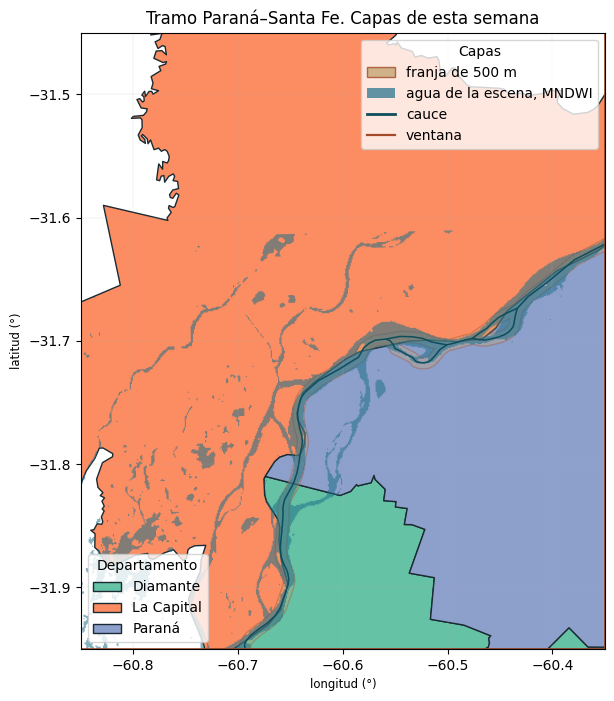

Mapa guardado en mapa_ejercicio.png
faltan: []


In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
if "limite_tramo" in capas:
    limite = capas["limite_tramo"]
    columna = "departamento" if "departamento" in limite.columns else None
    limite.plot(
        ax=ax,
        column=columna,
        categorical=True,
        cmap="Set2",
        edgecolor="#1A2A32",
        legend=columna is not None,
        legend_kwds={"title": "Departamento", "loc": "lower left"},
    )
if "franja_500m" in capas:
    capas["franja_500m"].plot(
        ax=ax, facecolor="#C4A574", alpha=0.35, edgecolor="#A34A28"
    )
if "agua_mndwi" in capas:
    capas["agua_mndwi"].plot(ax=ax, color="#1F6F8A", alpha=0.55)
if "cauce" in capas:
    capas["cauce"].plot(ax=ax, color="#0E4D5C", linewidth=1.1)
ventana.boundary.plot(ax=ax, color="#A34A28", linewidth=1.2)

leyenda_deptos = ax.get_legend()
handles = []
if "franja_500m" in capas:
    handles.append(Patch(facecolor="#C4A574", edgecolor="#A34A28", alpha=0.8, label="franja de 500 m"))
if "agua_mndwi" in capas:
    handles.append(Patch(facecolor="#1F6F8A", alpha=0.7, label="agua de la escena, MNDWI"))
if "cauce" in capas:
    handles.append(Line2D([0], [0], color="#0E4D5C", lw=2, label="cauce"))
handles.append(Line2D([0], [0], color="#A34A28", lw=1.6, label="ventana"))
ax.legend(handles=handles, title="Capas", loc="upper right")
if leyenda_deptos is not None:
    ax.add_artist(leyenda_deptos)
cerrar(ax, "Tramo Paraná–Santa Fe. Capas de esta semana")
fig.savefig("mapa_ejercicio.png", dpi=120, bbox_inches="tight")
plt.show()
print("Mapa guardado en mapa_ejercicio.png")
print("faltan:", [n for n in PEDIDAS if n not in capas])


### Párrafo, en tus palabras

Reemplazá los huecos. No dejes las preguntas solas. El límite de +2 m, +4 m y +6 m va en tu texto, no como consigna aparte.

Con las variables de esta semana, ¿qué áreas se agrupan entre sí?

…

Cuando el río sube, ¿qué se lee de esos grupos?

…

¿Qué haría que dos lugares fueran el mismo tipo de lugar?

…


In [6]:
# El mismo párrafo que vas a entregar. Reemplazá el texto.
PARRAFO = """
Con las variables de esta semana, las áreas que se agrupan son:
1) El sistema fluvial activo e islas de inundación, definido por la superposición del cauce principal del río Paraná y las masas de agua detectadas espectralmente mediante el índice MNDWI.
2) La ribera de interfase inmediata, delimitada geométricamente por la franja de amortiguación de 500 m adyacente al cauce que contacta con los bordes de los departamentos La Capital, Paraná y Diamante.
3) La terraza alta o territorio interior continental, situado dentro de los límites departamentales pero fuera de la franja de 500 m y sin presencia de agua libre en la fecha analizada.

Cuando el río sube, de esos grupos se lee:
Únicamente la condición de cobertura hídrica instantánea capturada por el sensor en esa fecha particular. Sin contar con un Modelo Digital de Elevación (DEM) ni datos topográficos de cota o pendiente, todavía no se puede predecir ni modelar el avance escalonado del agua ante crecidas de +2 m, +4 m y +6 m. La máscara de agua actual es una fotografía estática del nivel del río, no un modelo predictivo de susceptibilidad hídrica.

Dos lugares son del mismo tipo cuando:
Comparten la misma relación espacial respecto a la ribera (estar ambos dentro o fuera del buffer de 500 m del cauce), la misma pertenencia administrativa territorial y la presencia o ausencia simultánea de agua superficial registrada por el índice espectral en la escena.
"""

# Una oración para decir en voz alta la clase que viene. Completala.
LINEA = "Con el cauce, la franja de 500 m y el agua de esta escena, estos lugares son del mismo tipo porque comparten proximidad de ribera y cobertura hídrica instantánea. El río que sube en +2 m, +4 m y +6 m todavía no se lee: falta el terreno."

Path("respuesta_ejercicio.txt").write_text(
    PARRAFO.strip() + "\n\n" + LINEA.strip() + "\n",
    encoding="utf-8",
)
if "..." in PARRAFO or not LINEA.strip():
    print("Falta el párrafo o la línea. respuesta_ejercicio.txt quedó para que lo reemplaces.")
else:
    print("Quedó respuesta_ejercicio.txt")

Quedó respuesta_ejercicio.txt


## 4. Mostrar el resultado con IA generativa

La IA generativa entra solo para mostrar lo que ya está decidido. No hace el análisis y no elige los grupos. El mapa y el párrafo tienen que ser tuyos.

Pegá las capas, o una descripción más el GeoPackage, y pedí un visor web simple o un panel: una página Folium o Leaflet, o un panel chico con el mapa y tu párrafo.

Prompt listo para pegar:

```
Te paso un mapa que ya hice yo y un párrafo que ya escribí yo. No elijas grupos. No clasifiques lugares. No inventes capas. No cambies el párrafo. No agregues terreno, cotas ni una lectura de +2 m, +4 m o +6 m.

Armá un visor web simple: una página Folium o Leaflet, o un panel chico. Tiene que mostrar:
- el mapa con estas capas, cada una con su nombre: limite_tramo, cauce, franja_500m, agua_mndwi
- el párrafo tal como lo pego, debajo o al lado del mapa

Ventana: oeste -60.85, sur -31.95, este -60.35, norte -31.45. Norte arriba.
El lugar es el tramo Paraná–Santa Fe.
El agua es una capa de una escena, no una etiqueta y no un grupo.

Capas o archivo: [pegá acá la descripción de las capas, o adjuntá paquete_tramo.gpkg]
Párrafo: [pegá acá tu párrafo, el mismo de respuesta_ejercicio.txt]
```

Si te devuelve un html, guardalo como `visor_ejercicio.html` en esta sesión. Si te devuelve un link, anotalo en el párrafo. Con una de las dos cosas alcanza.


In [7]:
import folium

# 1. Coordenadas del centro de la ventana de cursada
lat_centro = (-31.95 + -31.45) / 2
lon_centro = (-60.85 + -60.35) / 2

# 2. Inicialización del mapa base interactivo
m = folium.Map(
    location=[lat_centro, lon_centro],
    zoom_start=11,
    tiles="CartoDB positron"
)

# 3. Capa: Límite de Departamentos (polígonos base)
if "limite_tramo" in capas:
    folium.GeoJson(
        capas["limite_tramo"],
        name="Límite Departamentos",
        style_function=lambda x: {
            "fillColor": "#a6cee3",
            "color": "#1A2A32",
            "weight": 1.2,
            "fillOpacity": 0.25,
        },
        tooltip=folium.GeoJsonTooltip(fields=["departamento"], aliases=["Departamento:"])
    ).add_to(m)

# 4. Capa: Franja de 500 m (buffer de amortiguación)
if "franja_500m" in capas:
    folium.GeoJson(
        capas["franja_500m"],
        name="Franja de 500 m",
        style_function=lambda x: {
            "fillColor": "#fdae61",
            "color": "#A34A28",
            "weight": 1,
            "fillOpacity": 0.45,
        }
    ).add_to(m)

# 5. Capa: Agua de la Escena (MNDWI > 0)
if "agua_mndwi" in capas:
    folium.GeoJson(
        capas["agua_mndwi"],
        name="Agua de la Escena (MNDWI)",
        style_function=lambda x: {
            "fillColor": "#1F6F8A",
            "color": "#1F6F8A",
            "weight": 0.5,
            "fillOpacity": 0.7,
        }
    ).add_to(m)

# 6. Capa: Cauce del Río Paraná (línea principal)
if "cauce" in capas:
    folium.GeoJson(
        capas["cauce"],
        name="Cauce Río Paraná",
        style_function=lambda x: {
            "color": "#0E4D5C",
            "weight": 2.2,
            "opacity": 0.9,
        }
    ).add_to(m)

# 7. Marco de la ventana de cursada
folium.GeoJson(
    ventana,
    name="Ventana de Cursada",
    style_function=lambda x: {
        "fillColor": "none",
        "color": "#A34A28",
        "weight": 1.5,
        "dashArray": "5, 5"
    }
).add_to(m)

# 8. Control interactivo de capas (arriba a la derecha)
folium.LayerControl(position="topright", collapsed=False).add_to(m)

# 9. Panel flotante integrado con tu análisis y conclusiones
panel_html = f"""
<div style="
    position: fixed;
    bottom: 20px; left: 20px; width: 420px; max-height: 380px;
    background-color: white; z-index: 9999; font-size: 12px;
    border: 2px solid #1A2A32; border-radius: 6px; padding: 12px;
    box-shadow: 0 4px 8px rgba(0,0,0,0.3); overflow-y: auto; font-family: sans-serif;
">
    <h4 style="margin-top: 0; color: #0E4D5C; margin-bottom: 6px;">Análisis Espacial: Tramo Paraná–Santa Fe</h4>
    <p style="text-align: justify; line-height: 1.35; color: #333; margin-bottom: 8px;">
        {PARRAFO.replace(chr(10), '<br>')}
    </p>
    <div style="background-color: #f0f4f8; padding: 6px; border-left: 3px solid #1F6F8A; font-style: italic; font-size: 11px;">
        <strong>Conclusión:</strong> {LINEA}
    </div>
</div>
"""
m.get_root().html.add_child(folium.Element(panel_html))

# 10. Guardar en disco el archivo requerido para la entrega
m.save("visor_ejercicio.html")
print("Visor interactivo generado exitosamente como 'visor_ejercicio.html'")

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Visor interactivo generado exitosamente como 'visor_ejercicio.html'


In [8]:
visor = Path("visor_ejercicio.html")
LINK_VISOR = ""  # si la IA te dio un link, pegalo entre las comillas

if visor.exists():
    print("Hay un visor:", visor.name, "bytes", visor.stat().st_size)
elif LINK_VISOR.strip():
    print("Visor por link:", LINK_VISOR.strip())
else:
    print("Todavía no hay visor_ejercicio.html ni link. El mapa y el párrafo igual son la entrega.")


Hay un visor: visor_ejercicio.html bytes 386128


## 5. Cómo se ve terminado

Está terminado cuando se puede abrir el mapa, leer el párrafo y abrir el visor, y las tres cosas dicen lo mismo.

- El mapa nombra las capas del tramo: límite, cauce, franja de 500 m y agua de la escena.
- El párrafo contesta las dos preguntas en tus palabras.
- El párrafo dice qué haría que dos lugares fueran el mismo tipo de lugar, a partir de cómo quedan juntas esas capas.
- El párrafo dice el límite: sin terreno no hay lectura de +2 m, +4 m y +6 m.
- El visor o el panel Muestra tu mapa y tu párrafo. No elige los grupos.
- La línea de abajo se puede decir en voz alta la clase que viene, ya completa.

La línea:

«Con el cauce, la franja de 500 m y el agua de esta escena, estos lugares son del mismo tipo porque ___. El río que sube en +2 m, +4 m y +6 m todavía no se lee: falta el terreno.»

Los huecos los completás con lo que vos viste en el mapa. Una línea genérica no alcanza.


In [9]:
linea_lista = bool(LINEA.strip()) and "___" not in LINEA
parrafo_listo = "..." not in PARRAFO and len(PARRAFO.split()) > 40
mapa_listo = Path("mapa_ejercicio.png").exists() and len(capas) == 4
visor_listo = Path("visor_ejercicio.html").exists() or bool(LINK_VISOR.strip())

print("mapa con las cuatro capas:", mapa_listo)
print("párrafo escrito:", parrafo_listo)
print("visor o link:", visor_listo)
print("línea para decir la clase que viene:", linea_lista)
if linea_lista:
    print(LINEA.strip())


mapa con las cuatro capas: True
párrafo escrito: True
visor o link: True
línea para decir la clase que viene: True
Con el cauce, la franja de 500 m y el agua de esta escena, estos lugares son del mismo tipo porque comparten proximidad de ribera y cobertura hídrica instantánea. El río que sube en +2 m, +4 m y +6 m todavía no se lee: falta el terreno.
